# Part 2: more training data from the hand-sorted photos (batch 3)

Batch 3 = 353 more farms. These are mixed-crop farms whose ground photo was sorted by hand into one of the 4 classes; their Google Earth views were collected and checked with the same steps as part 1 (status-bar reading, thumbnail match, one copy per distinct image).

Question: does adding these farms to the TRAINING folds improve the models? Scoring is on exactly the same development farms and folds as part 1, so the numbers are comparable. Batch 3 farms are never used for validation or testing.

Rule as in part 1: one change per model; a change is kept only if the pooled out-of-fold macro-F1 goes up.

## 0. Setup (same as part 1)

In [1]:
import os, time, json, math, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf, keras
from keras import layers
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, roc_auc_score, log_loss)
import joblib

SEED = 42
keras.utils.set_random_seed(SEED)
DATA = "data"                     # contains chips/ and chips_index.csv
FAST = os.environ.get("FAST") == "1"   # quick smoke test on a small subset
OUT = "outputs_smoke" if FAST else "outputs"; os.makedirs(OUT, exist_ok=True)
WEIGHTS_DIR = "weights"           # optional local ImageNet weights; otherwise Keras downloads them
CLASSES = ["alfalfa", "cereals", "palm", "palm_orchard"]; N = len(CLASSES)
COLORS = ["#2b6cb0", "#d98a00", "#1f7a5a", "#b03a3a"]
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1795489770.245902   13954 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795489771.311730   13954 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1 | GPU: []


## 1. Data and splits (same code as part 1, so the folds and the test set are identical)

In [2]:
idx = pd.read_csv(f"{DATA}/chips_index.csv")
print("all images:", len(idx), "| farms:", idx.farm.nunique())
print("images per year:", idx.year.value_counts().sort_index().to_dict())

idx = idx[idx.year >= 2021]                                             # keep images close to the 2023 survey
conflict = set(pd.read_csv(f"{DATA}/conflicting_farms.csv").farm)       # same view, different reported crop
idx = idx[~idx.farm.isin(conflict)].reset_index(drop=True)
if FAST: idx = idx[idx.farm.isin(idx.drop_duplicates("farm").groupby("label").head(70).farm)].reset_index(drop=True)
idx["y"] = idx.label.map(CLASSES.index)
print("kept images:", len(idx), "| farms:", idx.farm.nunique(), "| spatial clusters:", idx.cluster.nunique(), "| areas:", idx.area.nunique())
print("images per farm:", idx.groupby("farm").size().value_counts().sort_index().to_dict())
display(pd.crosstab(idx.label, idx.year, margins=True))

all images: 2132 | farms: 1162
images per year: {2012.0: 9, 2013.0: 3, 2016.0: 4, 2018.0: 223, 2019.0: 7, 2020.0: 35, 2021.0: 486, 2022.0: 331, 2023.0: 978, 2024.0: 1, 2025.0: 51}
kept images: 1839 | farms: 1122 | spatial clusters: 365 | areas: 66
images per farm: {1: 450, 2: 627, 3: 45}


year,2021.0,2022.0,2023.0,2024.0,2025.0,All
label,,,,,,
alfalfa,52,74,284,0,15,425
cereals,93,116,256,0,15,480
palm,257,73,295,1,10,636
palm_orchard,82,68,139,0,9,298
All,484,331,974,1,49,1839


In [3]:
# Test set = whole spatial clusters (farms within 600 m of each other stay together), about 20% of farms.
farms = idx.drop_duplicates("farm")[["farm", "y", "cluster", "area"]].reset_index(drop=True)
sgk = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_i, test_i = next(sgk.split(farms, farms.y, farms.cluster))
idx["split"] = np.where(idx.farm.isin(set(farms.farm[test_i])), "test", "dev")

# Development set: 5 folds, again grouped by spatial cluster
dev_f = farms.iloc[dev_i].reset_index(drop=True); fold_of = {}
for k, (_, va) in enumerate(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(dev_f, dev_f.y, dev_f.cluster)):
    fold_of.update({f: k for f in dev_f.farm[va]})
idx["fold"] = idx.farm.map(fold_of).fillna(-1).astype(int)

assert not set(idx.cluster[idx.split == "test"]) & set(idx.cluster[idx.split == "dev"])
for k in range(5):
    assert not set(idx.cluster[idx.fold == k]) & set(idx.cluster[(idx.fold != k) & (idx.split == "dev")])

DEV = np.where(idx.split == "dev")[0]; TEST = np.where(idx.split == "test")[0]; y = idx.y.to_numpy(dtype=np.int64)
tab = pd.crosstab(idx.label, idx.fold.map(lambda k: f"fold {k + 1}" if k >= 0 else "test"))
tab["farms"] = idx.drop_duplicates("farm").label.value_counts()
display(tab)
maj = np.bincount(y[DEV]).argmax()
print(f"baseline (always '{CLASSES[maj]}'): dev accuracy {np.mean(y[DEV] == maj):.3f} | test accuracy {np.mean(y[TEST] == maj):.3f} | macro-F1 {f1_score(y[TEST], np.full(len(TEST), maj), average='macro'):.3f}")

fold,fold 1,fold 2,fold 3,fold 4,fold 5,test,farms
label,,,,,,,
alfalfa,66,65,60,81,58,95,297
cereals,66,88,80,81,74,91,291
palm,103,97,130,92,96,118,352
palm_orchard,49,48,49,49,51,52,182


baseline (always 'palm'): dev accuracy 0.349 | test accuracy 0.331 | macro-F1 0.124


In [4]:
def load(path, ctx, px):
    im = Image.open(f"{DATA}/{path}").convert("RGB")
    if ctx == 290: im = im.crop((128, 128, 384, 384))
    return np.asarray(im.resize((px, px), Image.BILINEAR), dtype=np.uint8)
X224 = {580: np.stack([load(p, 580, 224) for p in idx.image])}; X128 = {580: np.stack([load(p, 580, 128) for p in idx.image])}
cfg = json.load(open(f"{OUT}/models/config.json")); cnn_cfg = {k: tuple(v) if isinstance(v, list) else v for k, v in cfg["cnn"].items()}; tl = cfg["transfer"]
print("part 1 final settings -> CNN from scratch:", cnn_cfg, "| transfer:", tl)

part 1 final settings -> CNN from scratch: {'filters': (32, 64, 128), 'augment': True, 'dropout': 0.0} | transfer: {'backbone': 'densenet121', 'ctx': 580, 'rotations': False, 'head': 'dense'}


## 2. Batch 3 and which folds may use it

batch 3 images: 649 | farms: 353
dropped (linked to test clusters): 142 images
used: 440 images | 264 farms | farms whose label disagrees with the survey crops: 17


blocked,blocked in fold 1,"blocked in fold 1,2","blocked in fold 1,5",blocked in fold 2,"blocked in fold 2,4",blocked in fold 3,"blocked in fold 3,5",blocked in fold 4,"blocked in fold 4,5",blocked in fold 5,usable in every fold
label,,,,,,,,,,,
alfalfa,1,0,4,12,0,9,5,6,4,16,61
cereals,2,0,0,8,0,6,15,14,2,4,53
palm,10,0,1,3,0,0,2,8,0,10,31
palm_orchard,10,3,1,11,2,8,2,21,6,22,67


batch 3 farms per class: {'palm_orchard': 91, 'alfalfa': 72, 'cereals': 61, 'palm': 40}
part-1 dev farms per class: {'palm': 282, 'cereals': 232, 'alfalfa': 211, 'palm_orchard': 145}


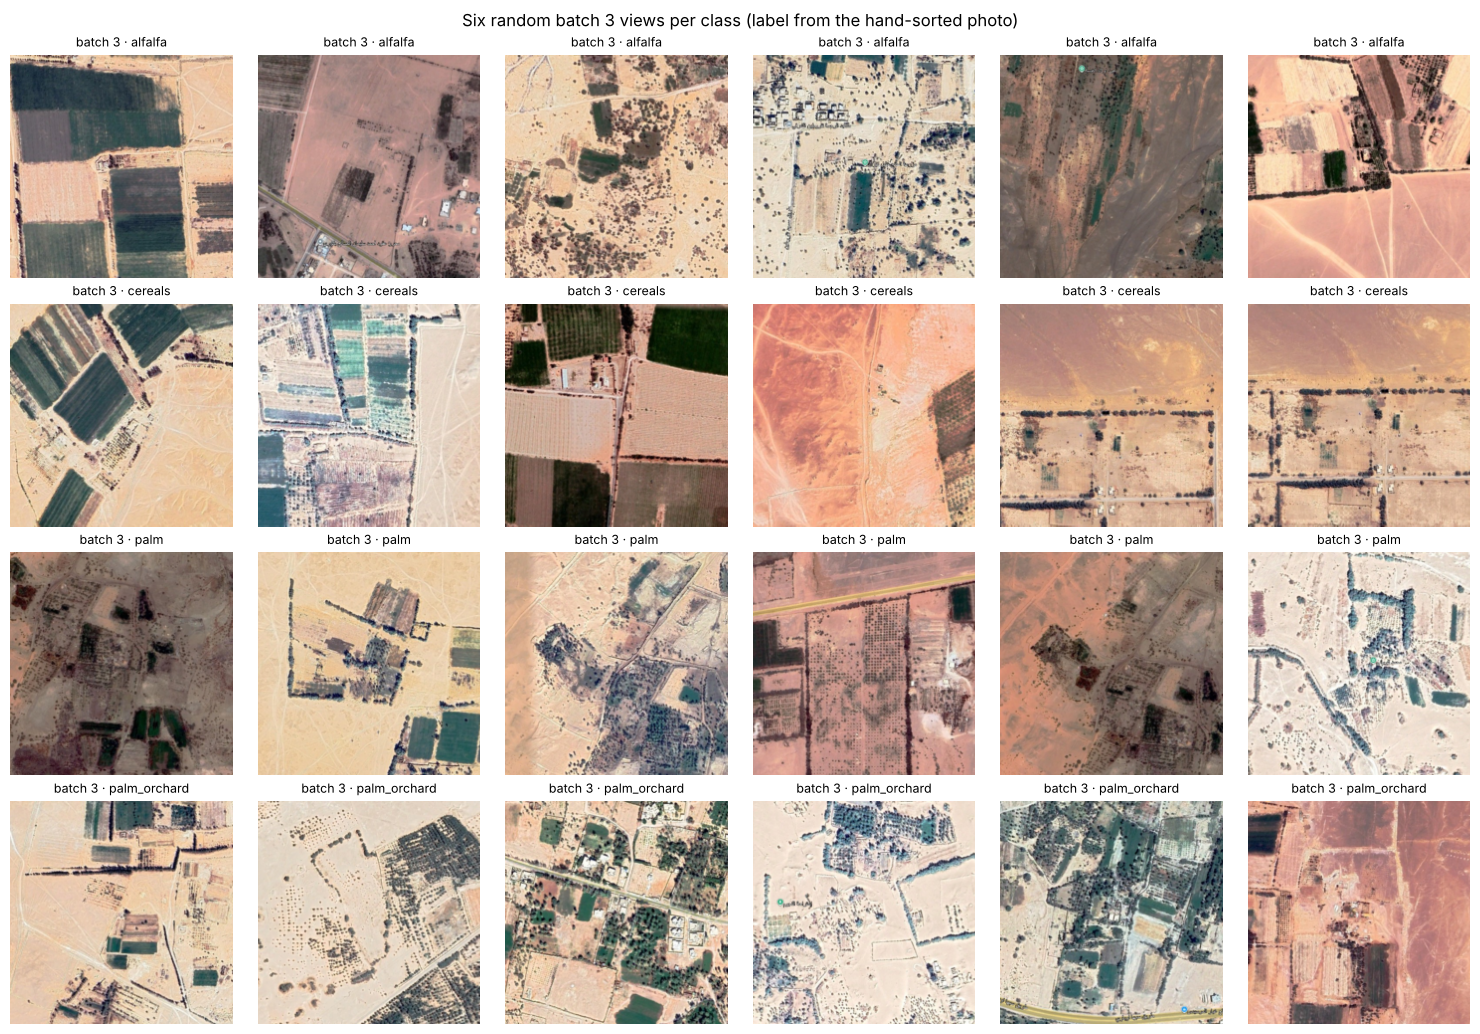

In [5]:
b3 = pd.read_csv(f"{DATA}/chips_index_batch3.csv", dtype={"link_clusters": str})
print("batch 3 images:", len(b3), "| farms:", b3.farm.nunique())
b3 = b3[b3.year >= 2021].reset_index(drop=True); b3["y"] = b3.label.map(CLASSES.index)

# A batch 3 farm within 600 m (chained) of a part-1 farm shares that farm's spatial cluster.
# - linked to a TEST cluster -> not used at all (it would leak the test areas into training)
# - linked to a dev cluster in fold k -> not used when fold k is the validation fold
test_cl = set(idx.cluster[idx.split == "test"]); fold_cl = idx[idx.split == "dev"].groupby("cluster").fold.first().to_dict()
links = b3.link_clusters.fillna("").astype(str).str.split()
b3["to_test"] = [any(int(c) in test_cl for c in l) for l in links]
b3["blocked"] = [sorted({fold_cl[int(c)] for c in l if int(c) in fold_cl}) for l in links]
b3 = b3[~b3.to_test].reset_index(drop=True)
print("dropped (linked to test clusters):", int(links.map(lambda l: any(int(c) in test_cl for c in l)).sum()), "images")
print("used:", len(b3), "images |", b3.farm.nunique(), "farms | farms whose label disagrees with the survey crops:", b3.drop_duplicates("farm").survey_conflict.sum())
display(pd.crosstab(b3.label, b3.blocked.map(lambda b: "blocked in fold " + ",".join(str(k + 1) for k in b) if b else "usable in every fold")))
print("batch 3 farms per class:", b3.drop_duplicates("farm").label.value_counts().to_dict())
print("part-1 dev farms per class:", idx[idx.split == "dev"].drop_duplicates("farm").label.value_counts().to_dict())

Xb224 = np.stack([load(p, 580, 224) for p in b3.image]); Xb128 = np.stack([load(p, 580, 128) for p in b3.image]); yb = b3.y.to_numpy(dtype=np.int64)
def b3_rows(k, drop_conflict=False):
    """Batch 3 rows allowed in training when fold k is the validation fold (k = -1: final model, all folds)."""
    ok = np.array([k not in b for b in b3.blocked]) if k >= 0 else np.ones(len(b3), bool)
    if drop_conflict: ok &= b3.survey_conflict.values == 0
    return np.where(ok)[0]

fig, ax = plt.subplots(4, 6, figsize=(15, 10.5))
for r, c in enumerate(CLASSES):
    for j, i in enumerate(b3[b3.label == c].sample(6, random_state=1).index):
        ax[r, j].imshow(Xb224[i]); ax[r, j].set_title(f"batch 3 · {c}", fontsize=9); ax[r, j].axis("off")
plt.suptitle("Six random batch 3 views per class (label from the hand-sorted photo)"); plt.tight_layout(); plt.savefig(f"{OUT}/samples_batch3.png", dpi=110); plt.show()

## 3. Helpers (same as part 1) and training functions that can add batch 3

In [6]:
RESULTS, OOF, HIST = [], {}, {}

def per_class_recall(yt, yp): return [float(np.mean(yp[yt == c] == c)) if np.any(yt == c) else np.nan for c in range(N)]

def farm_level(rows, P):
    df = pd.DataFrame(P, columns=CLASSES); df["farm"] = idx.farm.values[rows]; df["y"] = y[rows]
    g = df.groupby("farm").mean(numeric_only=True)
    return g.y.astype(int).values, g[CLASSES].values

def score(name, change, P, extra=None):
    yt = y[DEV]; yp = P.argmax(1); fy, fp = farm_level(DEV, P)
    row = {"model": name, "change": change, "val acc": accuracy_score(yt, yp), "val macro-F1": f1_score(yt, yp, average="macro"),
           "farm macro-F1": f1_score(fy, fp.argmax(1), average="macro"), "val log loss": log_loss(yt, np.clip(P, 1e-7, 1), labels=range(N))}
    row.update({f"recall {c}": r for c, r in zip(CLASSES, per_class_recall(yt, yp))}); row.update(extra or {})
    RESULTS.append(row); OOF[name] = P
    print(f"{name}: {change}\n  val acc {row['val acc']:.3f} | macro-F1 {row['val macro-F1']:.3f} | farm-level macro-F1 {row['farm macro-F1']:.3f} | log loss {row['val log loss']:.3f}")
    print("  recall per class:", {c: round(r, 2) for c, r in zip(CLASSES, per_class_recall(yt, yp))})
    return row

def table(names=None):
    t = pd.DataFrame(RESULTS).set_index("model")
    return (t.loc[names] if names else t).round(3)

def better(new, old): return new["val macro-F1"] > old["val macro-F1"]

class PerClass(keras.callbacks.Callback):
    """Validation recall of each class after every epoch (fold 1 only)."""
    def __init__(self, Xv, yv): super().__init__(); self.Xv, self.yv, self.v = Xv, yv, []
    def on_epoch_end(self, epoch, logs=None):
        self.v.append(per_class_recall(self.yv, self.model.predict(self.Xv, verbose=0).argmax(1)))

def plot_curves(name):
    h = HIST[name]; e = range(1, len(h["loss"]) + 1); best = int(np.argmin(h["val_loss"])) + 1
    fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
    for a, m in zip(ax[:2], ["accuracy", "loss"]):
        a.plot(e, h[m], label="train"); a.plot(e, h["val_" + m], label="validation"); a.axvline(best, ls=":", c="gray"); a.set_title(f"{name}: {m} (fold 1)"); a.set_xlabel("epoch"); a.legend()
    pc = np.array(h["per_class"])
    for c in range(N): ax[2].plot(e, pc[:, c], c=COLORS[c], label=CLASSES[c])
    ax[2].axvline(best, ls=":", c="gray"); ax[2].set_ylim(0, 1); ax[2].set_title("validation recall per class (fold 1)"); ax[2].set_xlabel("epoch"); ax[2].legend(fontsize=8)
    plt.tight_layout(); plt.savefig(f"{OUT}/curves_{name}.png", dpi=110); plt.show()

In [7]:
def make_ds(X, yy, train, bs=32):
    ds = tf.data.Dataset.from_tensor_slices((X, yy))
    if train:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(bs).prefetch(tf.data.AUTOTUNE)

def rot_flip(x):
    """A satellite view has no 'up': any 90-degree rotation or flip is still a valid view of the same farm."""
    x = tf.image.rot90(x, tf.random.uniform([], 0, 4, dtype=tf.int32))
    return tf.image.random_flip_left_right(x)

class RotFlip(layers.Layer):
    def call(self, x, training=None):
        return tf.map_fn(rot_flip, x) if training else x

def build_cnn(filters=(32, 64, 128), augment=False, dropout=0.0, px=128):
    keras.utils.set_random_seed(SEED)
    inp = keras.Input((px, px, 3)); x = RotFlip()(inp) if augment else inp
    x = layers.Rescaling(1 / 255)(x)
    for f in filters:
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization(momentum=0.9)(x); x = layers.Activation("relu")(x); x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    if dropout: x = layers.Dropout(dropout)(x)
    return keras.Model(inp, layers.Dense(N, activation="softmax")(x))

def run_cnn(name, change, ctx=580, max_epochs=30, patience=6, lr=1e-3, **kw):
    max_epochs = 2 if FAST else max_epochs; X = X128[ctx]; P = np.zeros((len(DEV), N)); epochs = []; t = time.time()
    for k in range(5):
        tr = DEV[idx.fold.values[DEV] != k]; va = DEV[idx.fold.values[DEV] == k]
        m = build_cnn(**kw); m.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        cb = [keras.callbacks.EarlyStopping("val_loss", patience=patience, restore_best_weights=True)]
        if k == 0: pcb = PerClass(X[va], y[va]); cb.append(pcb)
        h = m.fit(make_ds(X[tr], y[tr], True), validation_data=make_ds(X[va], y[va], False), epochs=max_epochs, callbacks=cb, verbose=0).history
        if k == 0: HIST[name] = {**h, "per_class": pcb.v}
        P[np.searchsorted(DEV, va)] = m.predict(X[va], verbose=0); epochs.append(int(np.argmin(h["val_loss"])) + 1)
    row = score(name, change, P, {"weights": m.count_params(), "best epochs": epochs, "time (s)": round(time.time() - t)})
    plot_curves(name); return row

In [8]:
BACKBONES = {
    "resnet50": (keras.applications.ResNet50, keras.applications.resnet50.preprocess_input, "resnet50_weights_tf_dim_ordering_tf_kernels_notop.h5"),
    "densenet121": (keras.applications.DenseNet121, keras.applications.densenet.preprocess_input, "densenet121_weights_tf_dim_ordering_tf_kernels_notop.h5"),
}
def backbone(name):
    fn, pre, wfile = BACKBONES[name]; local = os.path.join(WEIGHTS_DIR, wfile)
    m = fn(include_top=False, weights=None if os.path.exists(local) else "imagenet", input_shape=(224, 224, 3), pooling="avg")
    if os.path.exists(local): m.load_weights(local)
    return m, pre

def features(name, ctx):
    """Pooled features of every image in its 4 rotations -> array (4, n_images, d). Cached on disk."""
    path = f"{OUT}/features_{name}_{ctx}.npy"
    if os.path.exists(path): return np.load(path)
    m, pre = backbone(name); t = time.time()
    F = np.stack([m.predict(pre(np.rot90(X224[ctx], r, axes=(1, 2)).astype("float32")), batch_size=32, verbose=0) for r in range(4)])
    np.save(path, F); print(f"features {name} {ctx} m: {F.shape} in {time.time() - t:.0f} s"); return F

def lr_head(): return make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=5000))

def run_lr(name, change, F, rotations=False):
    P = np.zeros((len(DEV), N)); t = time.time()
    for k in range(5):
        tr = DEV[idx.fold.values[DEV] != k]; va = DEV[idx.fold.values[DEV] == k]
        R = range(4) if rotations else range(1)
        clf = lr_head().fit(np.concatenate([F[r][tr] for r in R]), np.tile(y[tr], len(R)))
        P[np.searchsorted(DEV, va)] = np.mean([clf.predict_proba(F[r][va]) for r in R], axis=0)
    return score(name, change, P, {"weights": (F.shape[2] + 1) * N, "time (s)": round(time.time() - t)})

In [9]:
def dense_head(d):
    keras.utils.set_random_seed(SEED)
    inp = keras.Input((d,)); x = layers.Dense(256, activation="relu")(inp); x = layers.Dropout(0.4)(x)
    return keras.Model(inp, layers.Dense(N, activation="softmax")(x))

def features_b3(name, ctx=580):
    path = f"{OUT}/features_batch3_{name}_{ctx}.npy"
    if os.path.exists(path) and np.load(path).shape[1] == len(b3): return np.load(path)
    m, pre = backbone(name); F = np.stack([m.predict(pre(np.rot90(Xb224, r, axes=(1, 2)).astype("float32")), batch_size=32, verbose=0) for r in range(4)])
    np.save(path, F); return F

def run_cnn2(name, change, use_b3=False, drop_conflict=False, max_epochs=30, patience=6, lr=1e-3, **kw):
    max_epochs = 2 if FAST else max_epochs; X = X128[580]; P = np.zeros((len(DEV), N)); epochs = []; t = time.time(); n_extra = []
    for k in range(5):
        tr = DEV[idx.fold.values[DEV] != k]; va = DEV[idx.fold.values[DEV] == k]
        Xtr, ytr = X[tr], y[tr]
        if use_b3: e = b3_rows(k, drop_conflict); Xtr, ytr = np.concatenate([Xtr, Xb128[e]]), np.concatenate([ytr, yb[e]]); n_extra.append(len(e))
        m = build_cnn(**kw); m.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        cb = [keras.callbacks.EarlyStopping("val_loss", patience=patience, restore_best_weights=True)]
        if k == 0: pcb = PerClass(X[va], y[va]); cb.append(pcb)
        h = m.fit(make_ds(Xtr, ytr, True), validation_data=make_ds(X[va], y[va], False), epochs=max_epochs, callbacks=cb, verbose=0).history
        if k == 0: HIST[name] = {**h, "per_class": pcb.v}
        P[np.searchsorted(DEV, va)] = m.predict(X[va], verbose=0); epochs.append(int(np.argmin(h["val_loss"])) + 1)
    row = score(name, change, P, {"weights": m.count_params(), "best epochs": epochs, "batch 3 images per fold": n_extra, "time (s)": round(time.time() - t)})
    plot_curves(name); return row

def run_dense2(name, change, use_b3=False, drop_conflict=False, max_epochs=100, patience=10):
    max_epochs = 2 if FAST else max_epochs; F = features(tl["backbone"], tl["ctx"]); Fb = features_b3(tl["backbone"], tl["ctx"])
    P = np.zeros((len(DEV), N)); t = time.time(); epochs = []; n_extra = []
    mu, sd = F[0][DEV].mean(0), F[0][DEV].std(0) + 1e-6; Fz, Fbz = (F - mu) / sd, (Fb - mu) / sd
    R = range(4) if tl["rotations"] else range(1)
    for k in range(5):
        tr = DEV[idx.fold.values[DEV] != k]; va = DEV[idx.fold.values[DEV] == k]
        Xtr, ytr = np.concatenate([Fz[r][tr] for r in R]), np.tile(y[tr], len(R))
        if use_b3:
            e = b3_rows(k, drop_conflict); n_extra.append(len(e))
            Xtr, ytr = np.concatenate([Xtr] + [Fbz[r][e] for r in R]), np.concatenate([ytr, np.tile(yb[e], len(R))])
        m = dense_head(F.shape[2]); m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        cb = [keras.callbacks.EarlyStopping("val_loss", patience=patience, restore_best_weights=True)]
        if k == 0: pcb = PerClass(Fz[0][va], y[va]); cb.append(pcb)
        h = m.fit(Xtr, ytr, validation_data=(Fz[0][va], y[va]), epochs=max_epochs, batch_size=64, callbacks=cb, verbose=0).history
        if k == 0: HIST[name] = {**h, "per_class": pcb.v}
        P[np.searchsorted(DEV, va)] = np.mean([m.predict(Fz[r][va], verbose=0) for r in R], axis=0); epochs.append(int(np.argmin(h["val_loss"])) + 1)
    row = score(name, change, P, {"weights": m.count_params(), "best epochs": epochs, "batch 3 images per fold": n_extra, "time (s)": round(time.time() - t)})
    plot_curves(name); return row

## 4. Experiments (one change each)

S1: part-1 final CNN from scratch (3 blocks, rotations/flips)
  val acc 0.455 | macro-F1 0.360 | farm-level macro-F1 0.367 | log loss 1.248
  recall per class: {'alfalfa': 0.17, 'cereals': 0.6, 'palm': 0.72, 'palm_orchard': 0.07}


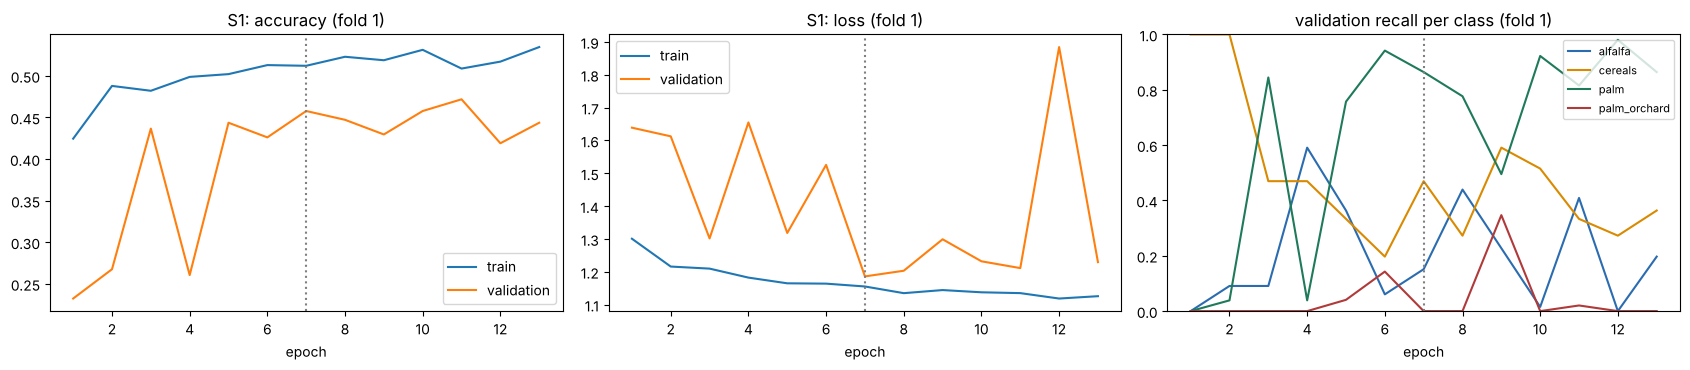

T5: part-1 final transfer model (DenseNet121, 580 m, dense head)
  val acc 0.469 | macro-F1 0.430 | farm-level macro-F1 0.442 | log loss 1.408
  recall per class: {'alfalfa': 0.43, 'cereals': 0.46, 'palm': 0.62, 'palm_orchard': 0.22}


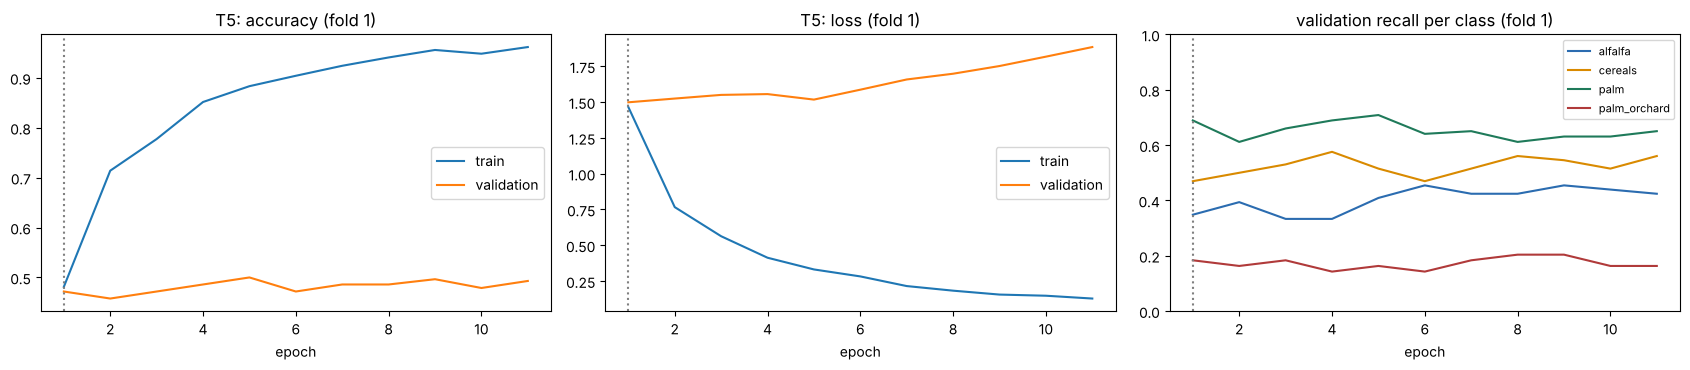

In [10]:
# Reference rows: the part-1 final models, re-run here so every number in this table comes from the same session
s1 = run_cnn2("S1", "part-1 final CNN from scratch (3 blocks, rotations/flips)", **cnn_cfg)
t5 = run_dense2("T5", "part-1 final transfer model (DenseNet121, 580 m, dense head)")

S4: S1 + batch 3 farms in the training folds
  val acc 0.429 | macro-F1 0.349 | farm-level macro-F1 0.348 | log loss 1.269
  recall per class: {'alfalfa': 0.21, 'cereals': 0.54, 'palm': 0.65, 'palm_orchard': 0.07}


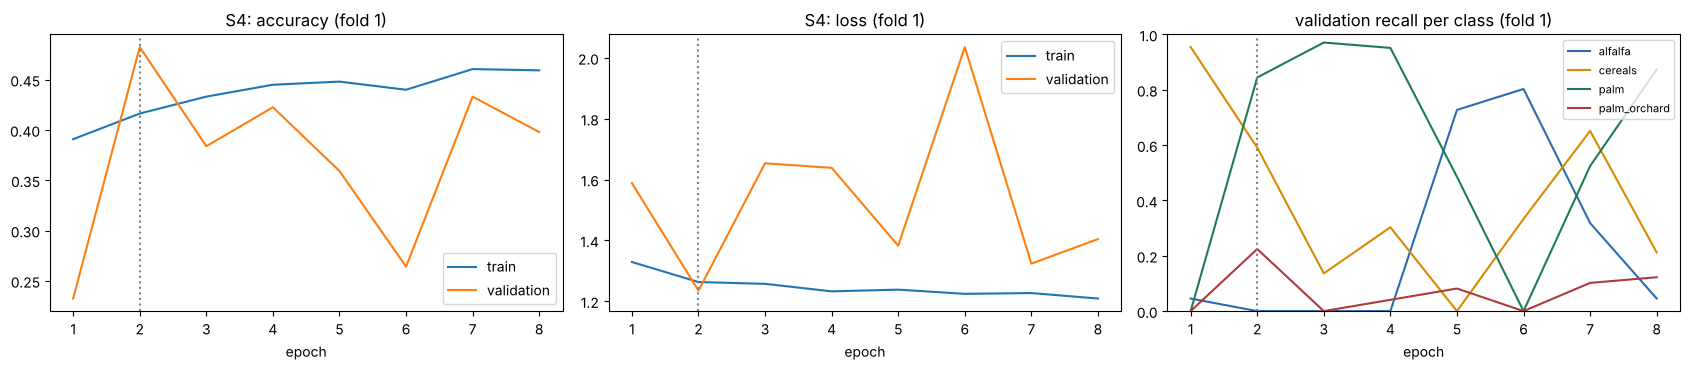

kept: S1


In [11]:
s4 = run_cnn2("S4", "S1 + batch 3 farms in the training folds", use_b3=True, **cnn_cfg)
best_s, best_s_row, best_s_kw = ("S4", s4, dict(use_b3=True)) if better(s4, s1) else ("S1", s1, dict())
print("kept:", best_s)

T6: T5 + batch 3 farms in the training folds
  val acc 0.430 | macro-F1 0.404 | farm-level macro-F1 0.426 | log loss 1.404
  recall per class: {'alfalfa': 0.37, 'cereals': 0.43, 'palm': 0.54, 'palm_orchard': 0.27}


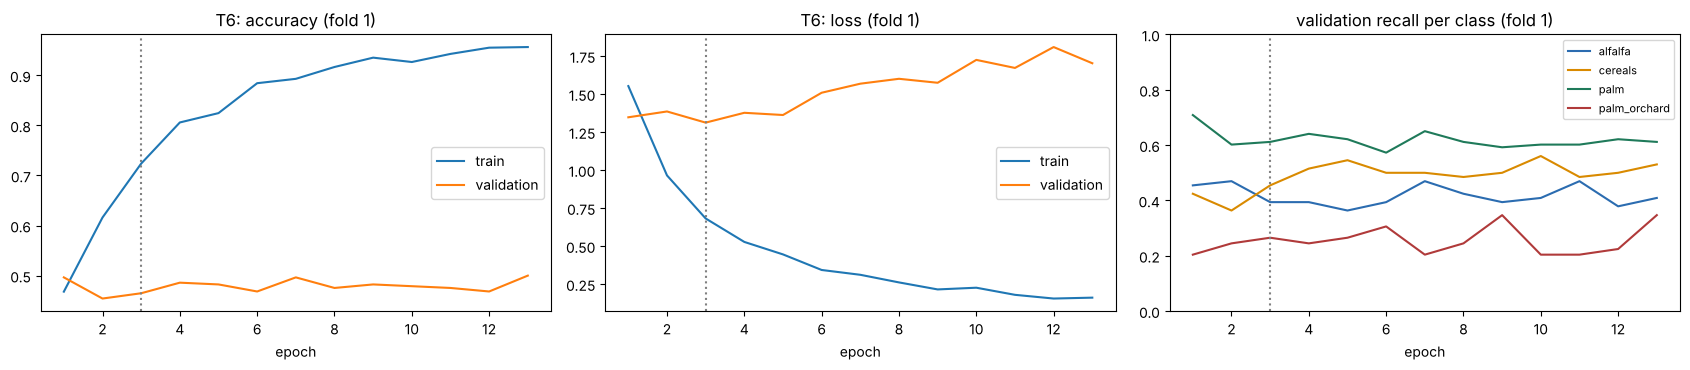

kept: T5


In [12]:
t6 = run_dense2("T6", "T5 + batch 3 farms in the training folds", use_b3=True)
best_t, best_t_row, best_t_kw = ("T6", t6, dict(use_b3=True)) if better(t6, t5) else ("T5", t5, dict())
print("kept:", best_t)

T7: T6 without the batch 3 farms whose photo label is not among the crops in the survey
  val acc 0.452 | macro-F1 0.420 | farm-level macro-F1 0.429 | log loss 1.437
  recall per class: {'alfalfa': 0.36, 'cereals': 0.43, 'palm': 0.61, 'palm_orchard': 0.28}


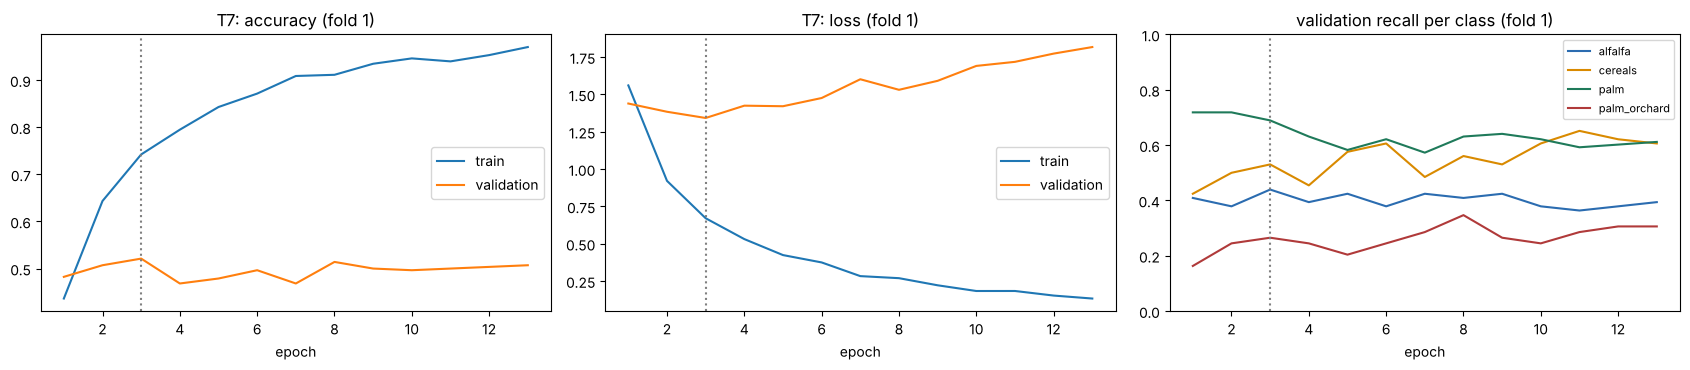

final transfer model: T5 {}


,change,val acc,val macro-F1,farm macro-F1,val log loss,recall alfalfa,recall cereals,recall palm,recall palm_orchard,weights,best epochs,batch 3 images per fold,time (s)
model,,,,,,,,,,,,,
S1,"part-1 final CNN from scratch (3 blocks, rotat...",0.455,0.360,0.367,1.248,0.167,0.596,0.718,0.065,94436,"[7, 10, 5, 4, 10]",[],1048
T5,"part-1 final transfer model (DenseNet121, 580 ...",0.469,0.430,0.442,1.408,0.430,0.455,0.624,0.215,263428,"[1, 1, 2, 1, 3]",[],14
S4,S1 + batch 3 farms in the training folds,0.429,0.349,0.348,1.269,0.212,0.537,0.654,0.073,94436,"[2, 17, 9, 4, 3]","[408, 401, 393, 377, 346]",1206
T6,T5 + batch 3 farms in the training folds,0.430,0.404,0.426,1.404,0.373,0.427,0.544,0.268,263428,"[3, 2, 1, 1, 4]","[408, 401, 393, 377, 346]",18
T7,T6 without the batch 3 farms whose photo label...,0.452,0.420,0.429,1.437,0.364,0.429,0.606,0.280,263428,"[3, 2, 1, 1, 2]","[380, 370, 367, 350, 321]",16


In [13]:
t7 = run_dense2("T7", "T6 without the batch 3 farms whose photo label is not among the crops in the survey", use_b3=True, drop_conflict=True)
if better(t7, best_t_row): best_t, best_t_row, best_t_kw = "T7", t7, dict(use_b3=True, drop_conflict=True)
print("final transfer model:", best_t, best_t_kw)
display(table()); table().to_csv(f"{OUT}/experiments_part2.csv")

,recall alfalfa,recall cereals,recall palm,recall palm_orchard,val macro-F1
model,,,,,
S1,0.167,0.596,0.718,0.065,0.360
T5,0.430,0.455,0.624,0.215,0.430
S4,0.212,0.537,0.654,0.073,0.349
T6,0.373,0.427,0.544,0.268,0.404
T7,0.364,0.429,0.606,0.280,0.420


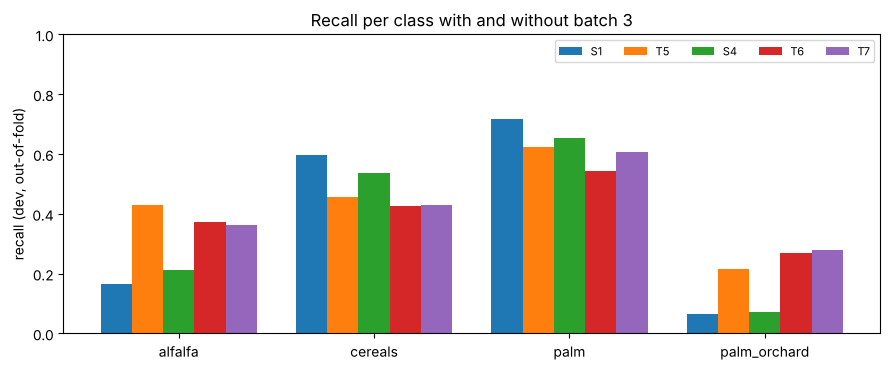

In [14]:
# Per-class recall, part-1 final models vs the batch 3 versions (development set, out-of-fold)
cols = [f"recall {c}" for c in CLASSES]
display(table()[cols + ["val macro-F1"]])
fig, ax = plt.subplots(figsize=(9, 3.8)); w = 0.8 / len(RESULTS)
for j, r in enumerate(RESULTS): ax.bar(np.arange(N) + j * w, [r[c] for c in cols], w, label=r["model"])
ax.set_xticks(np.arange(N) + 0.4 - w / 2); ax.set_xticklabels(CLASSES); ax.set_ylabel("recall (dev, out-of-fold)"); ax.set_ylim(0, 1); ax.legend(ncol=5, fontsize=8)
plt.title("Recall per class with and without batch 3"); plt.tight_layout(); plt.savefig(f"{OUT}/recall_part2.png", dpi=110); plt.show()

## 5. Test set (second use)

The test set was already used once in part 1. It is used here a second time, only to compare the part-1 models with the batch 3 models chosen above (the choice was made on the development folds only). Same test farms, same images.

In [15]:
def fit_cnn_final(use_b3=False, drop_conflict=False):
    row = s4 if use_b3 else s1; ep = int(np.median(row["best epochs"]))
    Xtr, ytr = X128[580][DEV], y[DEV]
    if use_b3: e = b3_rows(-1, drop_conflict); Xtr, ytr = np.concatenate([Xtr, Xb128[e]]), np.concatenate([ytr, yb[e]])
    m = build_cnn(**cnn_cfg); m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    m.fit(make_ds(Xtr, ytr, True), epochs=ep, verbose=0); return m

def fit_dense_final(row, use_b3=False, drop_conflict=False):
    F = features(tl["backbone"], tl["ctx"]); Fb = features_b3(tl["backbone"], tl["ctx"]); mu, sd = F[0][DEV].mean(0), F[0][DEV].std(0) + 1e-6
    Xtr, ytr = (F[0][DEV] - mu) / sd, y[DEV]
    if use_b3: e = b3_rows(-1, drop_conflict); Xtr, ytr = np.concatenate([Xtr, (Fb[0][e] - mu) / sd]), np.concatenate([ytr, yb[e]])
    m = dense_head(F.shape[2]); m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    m.fit(Xtr, ytr, epochs=int(np.median(row["best epochs"])), batch_size=64, verbose=0)
    return m, mu, sd, m.predict((F[0][TEST] - mu) / sd, verbose=0)

models = {}
cnn_old = keras.models.load_model(f"{OUT}/models/cnn_scratch.keras", custom_objects={"RotFlip": RotFlip}); models["CNN from scratch, part 1 (S1)"] = cnn_old.predict(X128[580][TEST], verbose=0)
if best_s != "S1": cnn_new = fit_cnn_final(**best_s_kw); models[f"CNN from scratch + batch 3 ({best_s})"] = cnn_new.predict(X128[580][TEST], verbose=0)
_, _, _, models["transfer, part 1 (T5)"] = fit_dense_final(t5)
if best_t != "T5": head_new, mu, sd, models[f"transfer + batch 3 ({best_t})"] = fit_dense_final(best_t_row, **best_t_kw)

yt = y[TEST]; summary = {}
for nm, P in models.items():
    fy, fp = farm_level(TEST, P)
    summary[nm] = {"accuracy": accuracy_score(yt, P.argmax(1)), "macro-F1": f1_score(yt, P.argmax(1), average="macro"),
                   "farm-level macro-F1": f1_score(fy, fp.argmax(1), average="macro"), "macro AUC (one-vs-rest)": roc_auc_score(yt, P, multi_class="ovr", average="macro"),
                   **{f"recall {c}": r for c, r in zip(CLASSES, per_class_recall(yt, P.argmax(1)))}}
summary = pd.DataFrame(summary).round(3); display(summary); summary.to_csv(f"{OUT}/test_summary_part2.csv")
print("part 1 test summary (saved file, for reference):"); display(pd.read_csv(f"{OUT}/test_summary.csv", index_col=0))

,"CNN from scratch, part 1 (S1)","transfer, part 1 (T5)"
accuracy,0.421,0.396
macro-F1,0.283,0.351
farm-level macro-F1,0.260,0.346
macro AUC (one-vs-rest),0.537,0.628
recall alfalfa,0.000,0.147
recall cereals,0.396,0.571
recall palm,0.949,0.568
recall palm_orchard,0.038,0.154


part 1 test summary (saved file, for reference):


,baseline,CNN from scratch (S1),transfer (T5)
test images,356.000,356.000,356.000
accuracy,0.331,0.421,0.396
macro-F1,0.124,0.283,0.351
farm-level accuracy,0.278,0.361,0.365
farm-level macro-F1,0.109,0.260,0.346
macro AUC (one-vs-rest),0.500,0.537,0.628
recall alfalfa,0.000,0.000,0.147
recall cereals,0.000,0.396,0.571
recall palm,1.000,0.949,0.568
recall palm_orchard,0.000,0.038,0.154


In [16]:
names = [n for n in models if "batch 3" in n]
if names:
    fig, ax = plt.subplots(1, len(names), figsize=(6.5 * len(names), 5.2), squeeze=False)
    for a, nm in zip(ax[0], names):
        ConfusionMatrixDisplay(confusion_matrix(yt, models[nm].argmax(1), labels=range(N)), display_labels=CLASSES).plot(ax=a, cmap="Greens", colorbar=False)
        a.set_title(f"{nm}, test images", fontsize=10); a.tick_params(axis="x", rotation=30)
    plt.tight_layout(); plt.savefig(f"{OUT}/test_confusion_part2.png", dpi=110); plt.show()

# Bootstrap over test farms: farm-level macro-F1 of each batch 3 model minus its part-1 version
rng = np.random.default_rng(SEED)
for new, old in [(n, "CNN from scratch, part 1 (S1)" if "CNN" in n else "transfer, part 1 (T5)") for n in names]:
    fy, f_new = farm_level(TEST, models[new]); _, f_old = farm_level(TEST, models[old]); d = []
    for _ in range(3000):
        s = rng.integers(0, len(fy), len(fy)); d.append(f1_score(fy[s], f_new[s].argmax(1), average="macro") - f1_score(fy[s], f_old[s].argmax(1), average="macro"))
    d = np.array(d); print(f"{new} minus {old}: {np.mean(d):+.3f}, 95% interval {np.percentile(d, 2.5):+.3f} to {np.percentile(d, 97.5):+.3f}, ahead in {np.mean(d > 0):.1%} of resamples")
if not names: print("Neither batch 3 model beat its part-1 version on the development folds, so the test set was not used again.")

Neither batch 3 model beat its part-1 version on the development folds, so the test set was not used again.


## 6. How well do the part-1 models agree with the batch 3 photo labels?

batch 3 farms: 264 | agreement with the photo label: accuracy 0.383, macro-F1 0.371
recall per class: {'alfalfa': 0.28, 'cereals': 0.67, 'palm': 0.4, 'palm_orchard': 0.26}


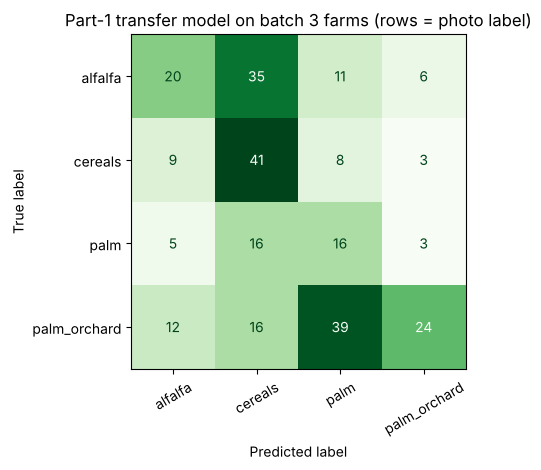

In [17]:
# Part-1 transfer model (trained on development farms only) applied to the batch 3 views: a check on the hand labels of mixed farms.
F = features(tl["backbone"], tl["ctx"]); Fb = features_b3(tl["backbone"], tl["ctx"]); mu1, sd1 = F[0][DEV].mean(0), F[0][DEV].std(0) + 1e-6
h1 = dense_head(F.shape[2]); h1.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h1.fit((F[0][DEV] - mu1) / sd1, y[DEV], epochs=int(np.median(t5["best epochs"])), batch_size=64, verbose=0)
Pb = h1.predict((Fb[0] - mu1) / sd1, verbose=0)
df = pd.DataFrame(Pb, columns=CLASSES); df["farm"] = b3.farm; df["y"] = yb; g = df.groupby("farm").mean(numeric_only=True)
fy, fp = g.y.astype(int).values, g[CLASSES].values
print(f"batch 3 farms: {len(fy)} | agreement with the photo label: accuracy {accuracy_score(fy, fp.argmax(1)):.3f}, macro-F1 {f1_score(fy, fp.argmax(1), average='macro'):.3f}")
print("recall per class:", {c: round(r, 2) for c, r in zip(CLASSES, per_class_recall(fy, fp.argmax(1)))})
ConfusionMatrixDisplay(confusion_matrix(fy, fp.argmax(1), labels=range(N)), display_labels=CLASSES).plot(cmap="Greens", colorbar=False)
plt.title("Part-1 transfer model on batch 3 farms (rows = photo label)"); plt.xticks(rotation=30); plt.tight_layout(); plt.savefig(f"{OUT}/batch3_agreement.png", dpi=110); plt.show()

## 7. Save the batch 3 models (only if they were kept)

In [18]:
os.makedirs(f"{OUT}/models_part2", exist_ok=True)
if best_s != "S1": cnn_new.save(f"{OUT}/models_part2/cnn_scratch.keras")
if best_t != "T5": head_new.save(f"{OUT}/models_part2/transfer_head.keras"); np.savez(f"{OUT}/models_part2/transfer_scaler.npz", mu=mu, sd=sd)
json.dump({"classes": CLASSES, "cnn": {"model": best_s, **{k: list(v) if isinstance(v, tuple) else v for k, v in cnn_cfg.items()}},
           "transfer": {**tl, "model": best_t, **best_t_kw}}, open(f"{OUT}/models_part2/config.json", "w"), indent=1)
print("kept models:", best_s, best_t)

kept models: S1 T5
